# PCA Correlation Analysis

This notebook analyzes the correlations between Principal Component (PC) scores and environmental factors (SST, SSS, SBT, SBS).

## Objectives
1. Load PCA scores and environmental data.
2. Calculate Pearson correlation coefficients between PC scores and environmental variables for each station.
3. Map these correlations to visualize the spatial distribution of relationships.

## Dependencies
- pandas
- geopandas
- matplotlib
- cartopy
- scipy (for correlation)


In [ ]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import numpy as np
from scipy.stats import pearsonr
import sys
from pathlib import Path
import shapely.wkb

# Add scripts to path
sys.path.append(str(Path.cwd().parent / 'scripts'))
from paths import ProjectPaths

# Configure plots
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['figure.dpi'] = 300

In [21]:
# 1. Load Data
# Load PCA Scores
pca_scores_path = ProjectPaths.PROCESSED_DATA_DIR / 'pca_scores.csv'
pca_scores = pd.read_csv(pca_scores_path, index_col=0)

# Load Environmental Data (Cleaned)
env_data_path = ProjectPaths.PROCESSED_DATA_DIR / 'merged_gdf_saisuipoin_cleaned.feather'
env_data_df = pd.read_feather(env_data_path)

# Convert WKB to Geometry
try:
    if 'geometry' in env_data_df.columns:
        # Check first element to see if bytes
        if isinstance(env_data_df['geometry'].iloc[0], bytes):
             env_data_df['geometry'] = env_data_df['geometry'].apply(lambda x: shapely.wkb.loads(x))
    
    env_data = gpd.GeoDataFrame(env_data_df, geometry='geometry', crs="EPSG:4326")
    print("Loaded Env Data with Geometry.")
except Exception as e:
    print(f"Error converting geometry: {e}")
    if 'latitude' in env_data_df.columns and 'longitude' in env_data_df.columns:
        env_data = gpd.GeoDataFrame(
            env_data_df, 
            geometry=gpd.points_from_xy(env_data_df.longitude, env_data_df.latitude),
            crs="EPSG:4326"
        )
        print("Loaded Env Data with Lat/Lon fallback.")

# Only convert zettaicode to string for merging later.
if 'zettaicode' in env_data.columns:
    env_data['zettaicode'] = env_data['zettaicode'].astype(str)

# Ensure zettaicode is string for merging
pca_scores.index = pca_scores.index.astype(str)
env_data['zettaicode'] = env_data['zettaicode'].astype(str)

# Filter for Summer (June, July, August)
# Use surveymont directly to avoid date parse errors with invalid days
env_data['month'] = env_data['surveymont']
summer_data = env_data[env_data['month'].isin([6, 7, 8])].copy()

print("Data Loaded:")
print(f"PCA Scores: {pca_scores.shape}")
print(f"Environmental Data (Summer): {summer_data.shape}")

Loaded Env Data with Geometry.
Data Loaded:
PCA Scores: (43, 43)
Environmental Data (Summer): (10694, 68)


In [22]:
# 2. Prepare Environmental Variables per Station

# Ensure numeric types for aggregation
for col in ['temp', 'salt']:
    if col in summer_data.columns:
        summer_data[col] = pd.to_numeric(summer_data[col], errors='coerce')

surface_data = summer_data[summer_data['saisuipoin'] == 1]
bottom_data = summer_data[summer_data['saisuipoin'] == 2]

def get_station_time_series(df, var_col):
    # Pivot to get Year x Station matrix
    # Assuming one value per year (summer mean)
    # Use surveyyear if available
    if 'surveyyear' in df.columns:
        df['year'] = df['surveyyear']
    elif 'date' in df.columns:
        df['year'] = pd.to_datetime(df['date']).dt.year
        
    matrix = df.groupby(['year', 'zettaicode'])[var_col].mean().unstack()
    return matrix

# Extract matrices
sst_matrix = get_station_time_series(surface_data, 'temp')
sss_matrix = get_station_time_series(surface_data, 'salt')
sbt_matrix = get_station_time_series(bottom_data, 'temp')
sbs_matrix = get_station_time_series(bottom_data, 'salt')

print("PCA Scores Index (should be Years based on EOF logic):", pca_scores.index)

PCA Scores Index (should be Years based on EOF logic): Index(['1981', '1982', '1983', '1984', '1985', '1986', '1987', '1988', '1989',
       '1990', '1991', '1992', '1993', '1994', '1995', '1996', '1997', '1998',
       '1999', '2000', '2001', '2002', '2003', '2004', '2005', '2006', '2007',
       '2008', '2009', '2010', '2011', '2012', '2013', '2014', '2015', '2016',
       '2017', '2018', '2019', '2020', '2021', '2022', '2023'],
      dtype='object')


/home/reyha/miniconda3/envs/sis_analysis/lib/python3.10/site-packages/geopandas/geodataframe.py:1969: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
/home/reyha/miniconda3/envs/sis_analysis/lib/python3.10/site-packages/geopandas/geodataframe.py:1969: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  super().__setitem__(key, value)
/home/reyha/miniconda3/envs/sis_analysis/lib/python3.10/site-packages/geopandas/geodataframe.py:1969: SettingWithCopyWarning: 
A value is trying to be s

In [ ]:
# 3. Calculate Correlations

def calculate_correlations(pc_scores, env_matrix, pc_col='PC1'):
    # pc_scores: Series (Year indexed)
    # env_matrix: DataFrame (Year x Station)
    
    correlations = {}
    p_values = {}

    # Ensure indices are integers for matching
    pc_scores.index = pc_scores.index.astype(int)
    env_matrix.index = env_matrix.index.astype(int)
    
    # Intersect years
    common_years = pc_scores.index.intersection(env_matrix.index)
    
    if len(common_years) < 5:
        print(f"Warning: Only {len(common_years)} common years for correlation.")
    
    for station in env_matrix.columns:
        # Get series
        s_env = env_matrix.loc[common_years, station]
        s_pc = pc_scores.loc[common_years]
        
        # Handle missing data
        valid = s_env.notna() & s_pc.notna()
        
        if valid.sum() > 5:
            corr, p = pearsonr(s_pc[valid], s_env[valid])
            correlations[station] = corr
            p_values[station] = p
        else:
            correlations[station] = np.nan
            p_values[station] = np.nan
            
    return pd.Series(correlations, name=f'{pc_col}_Corr'), pd.Series(p_values, name=f'{pc_col}_Pval')

# Initialize DataFrame to store station correlations
station_corrs = pd.DataFrame(index=sst_matrix.columns)
station_corrs.index.name = 'zettaicode'

# Calculate for PC1 and PC2 vs All 4 Env Vars
for pc in ['PC1', 'PC2']:
    if pc in pca_scores.columns:
        # SST
        r, p = calculate_correlations(pca_scores[pc], sst_matrix, pc)
        station_corrs[f'{pc}_SST_Corr'] = r
        
        # SSS
        r, p = calculate_correlations(pca_scores[pc], sss_matrix, pc)
        station_corrs[f'{pc}_SSS_Corr'] = r
        
        # SBT
        r, p = calculate_correlations(pca_scores[pc], sbt_matrix, pc)
        station_corrs[f'{pc}_SBT_Corr'] = r
        
        # SBS
        r, p = calculate_correlations(pca_scores[pc], sbs_matrix, pc)
        station_corrs[f'{pc}_SBS_Corr'] = r

# Merge with Geometry
gdf_stations = env_data.drop_duplicates(subset='zettaicode')[['zettaicode', 'geometry']].set_index('zettaicode')
corr_map_data = gdf_stations.join(station_corrs, how='inner')

print("Correlation Matrix Head:")
print(corr_map_data.head())

Correlation Matrix Head:
                              geometry  PC1_SST_Corr  PC1_SSS_Corr  \
zettaicode                                                           
00002811      POINT (135.33056 34.695)     -0.239075     -0.028239   
00002823    POINT (135.26389 34.65833)     -0.124316     -0.003171   
00000272    POINT (135.40917 34.65833)      0.017602     -0.034733   
00002725    POINT (135.26778 34.54861)     -0.223800      0.182278   
00000275    POINT (135.41222 34.55639)     -0.020927     -0.076264   

            PC1_SBT_Corr  PC1_SBS_Corr  PC2_SST_Corr  PC2_SSS_Corr  \
zettaicode                                                           
00002811       -0.312419      0.208352     -0.010651     -0.153126   
00002823       -0.188534     -0.072756     -0.022809      0.041681   
00000272        0.130947      0.335411     -0.206988     -0.067502   
00002725       -0.177557      0.243597      0.102950      0.128138   
00000275        0.043926      0.232150     -0.056888      0.0354

Saved plot to /home/reyha/SIS_Analysis_WSL/figures/pca_corr_SST.png


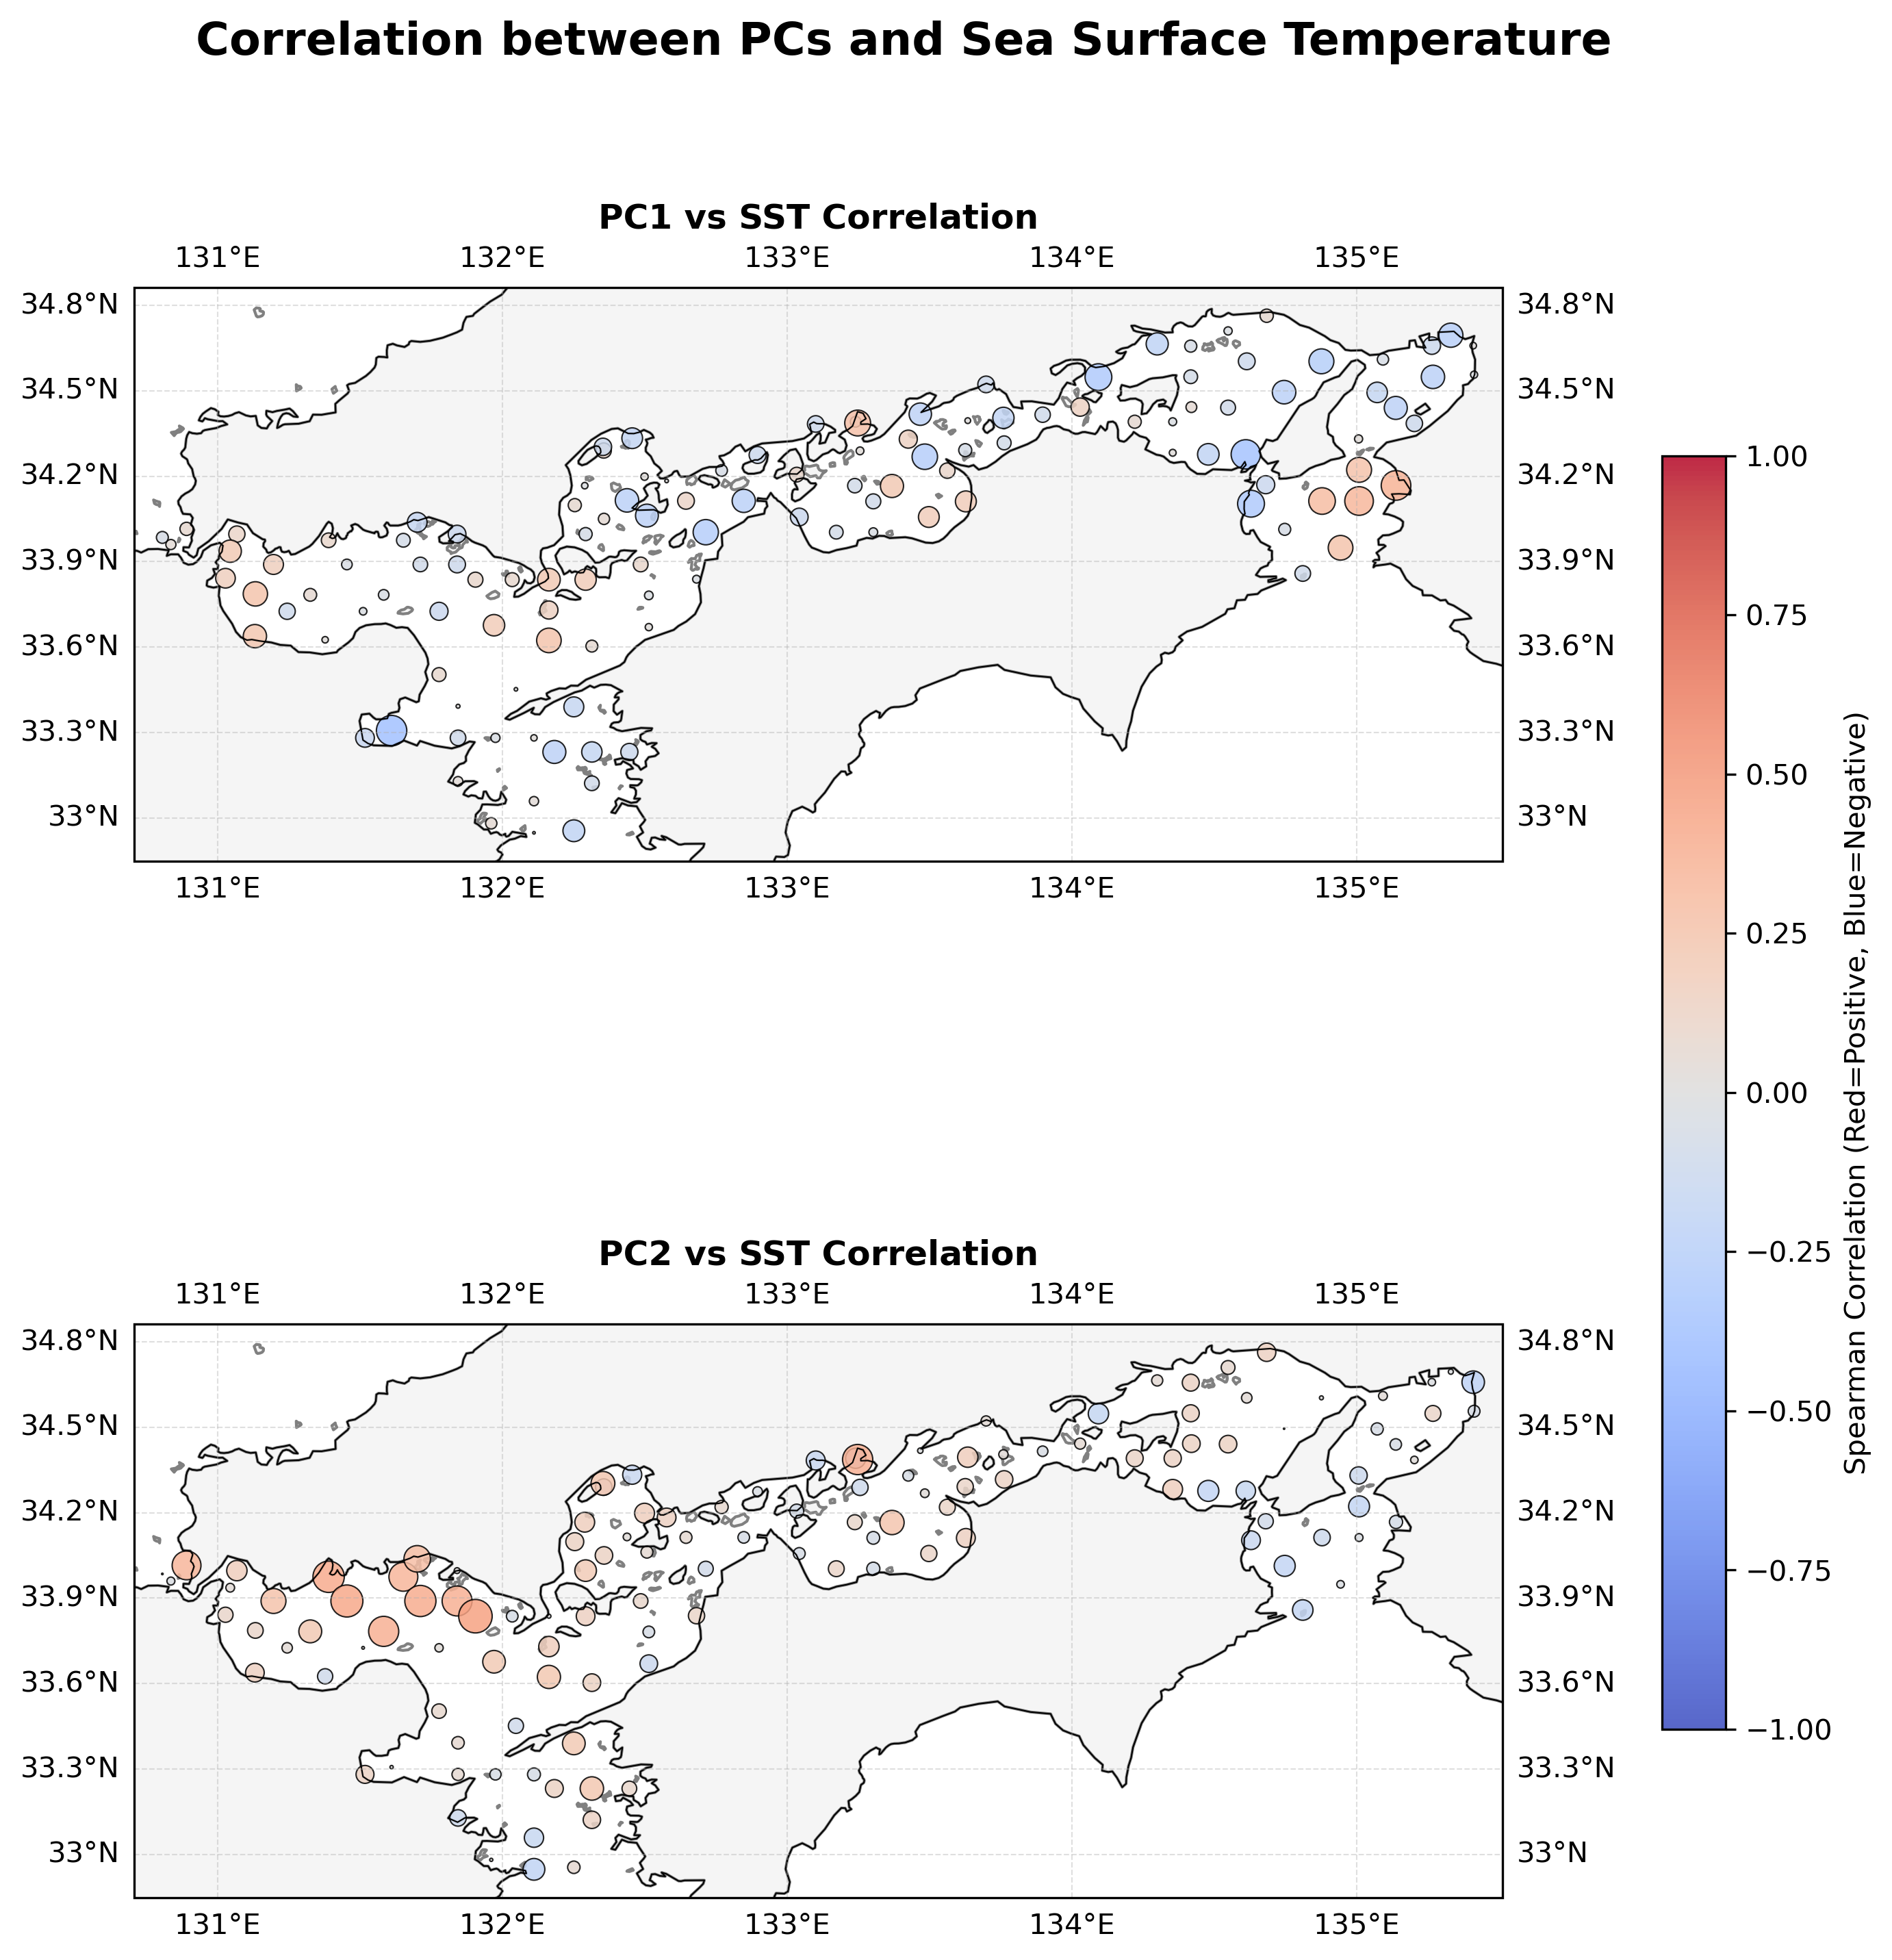

Saved plot to /home/reyha/SIS_Analysis_WSL/figures/pca_corr_SSS.png


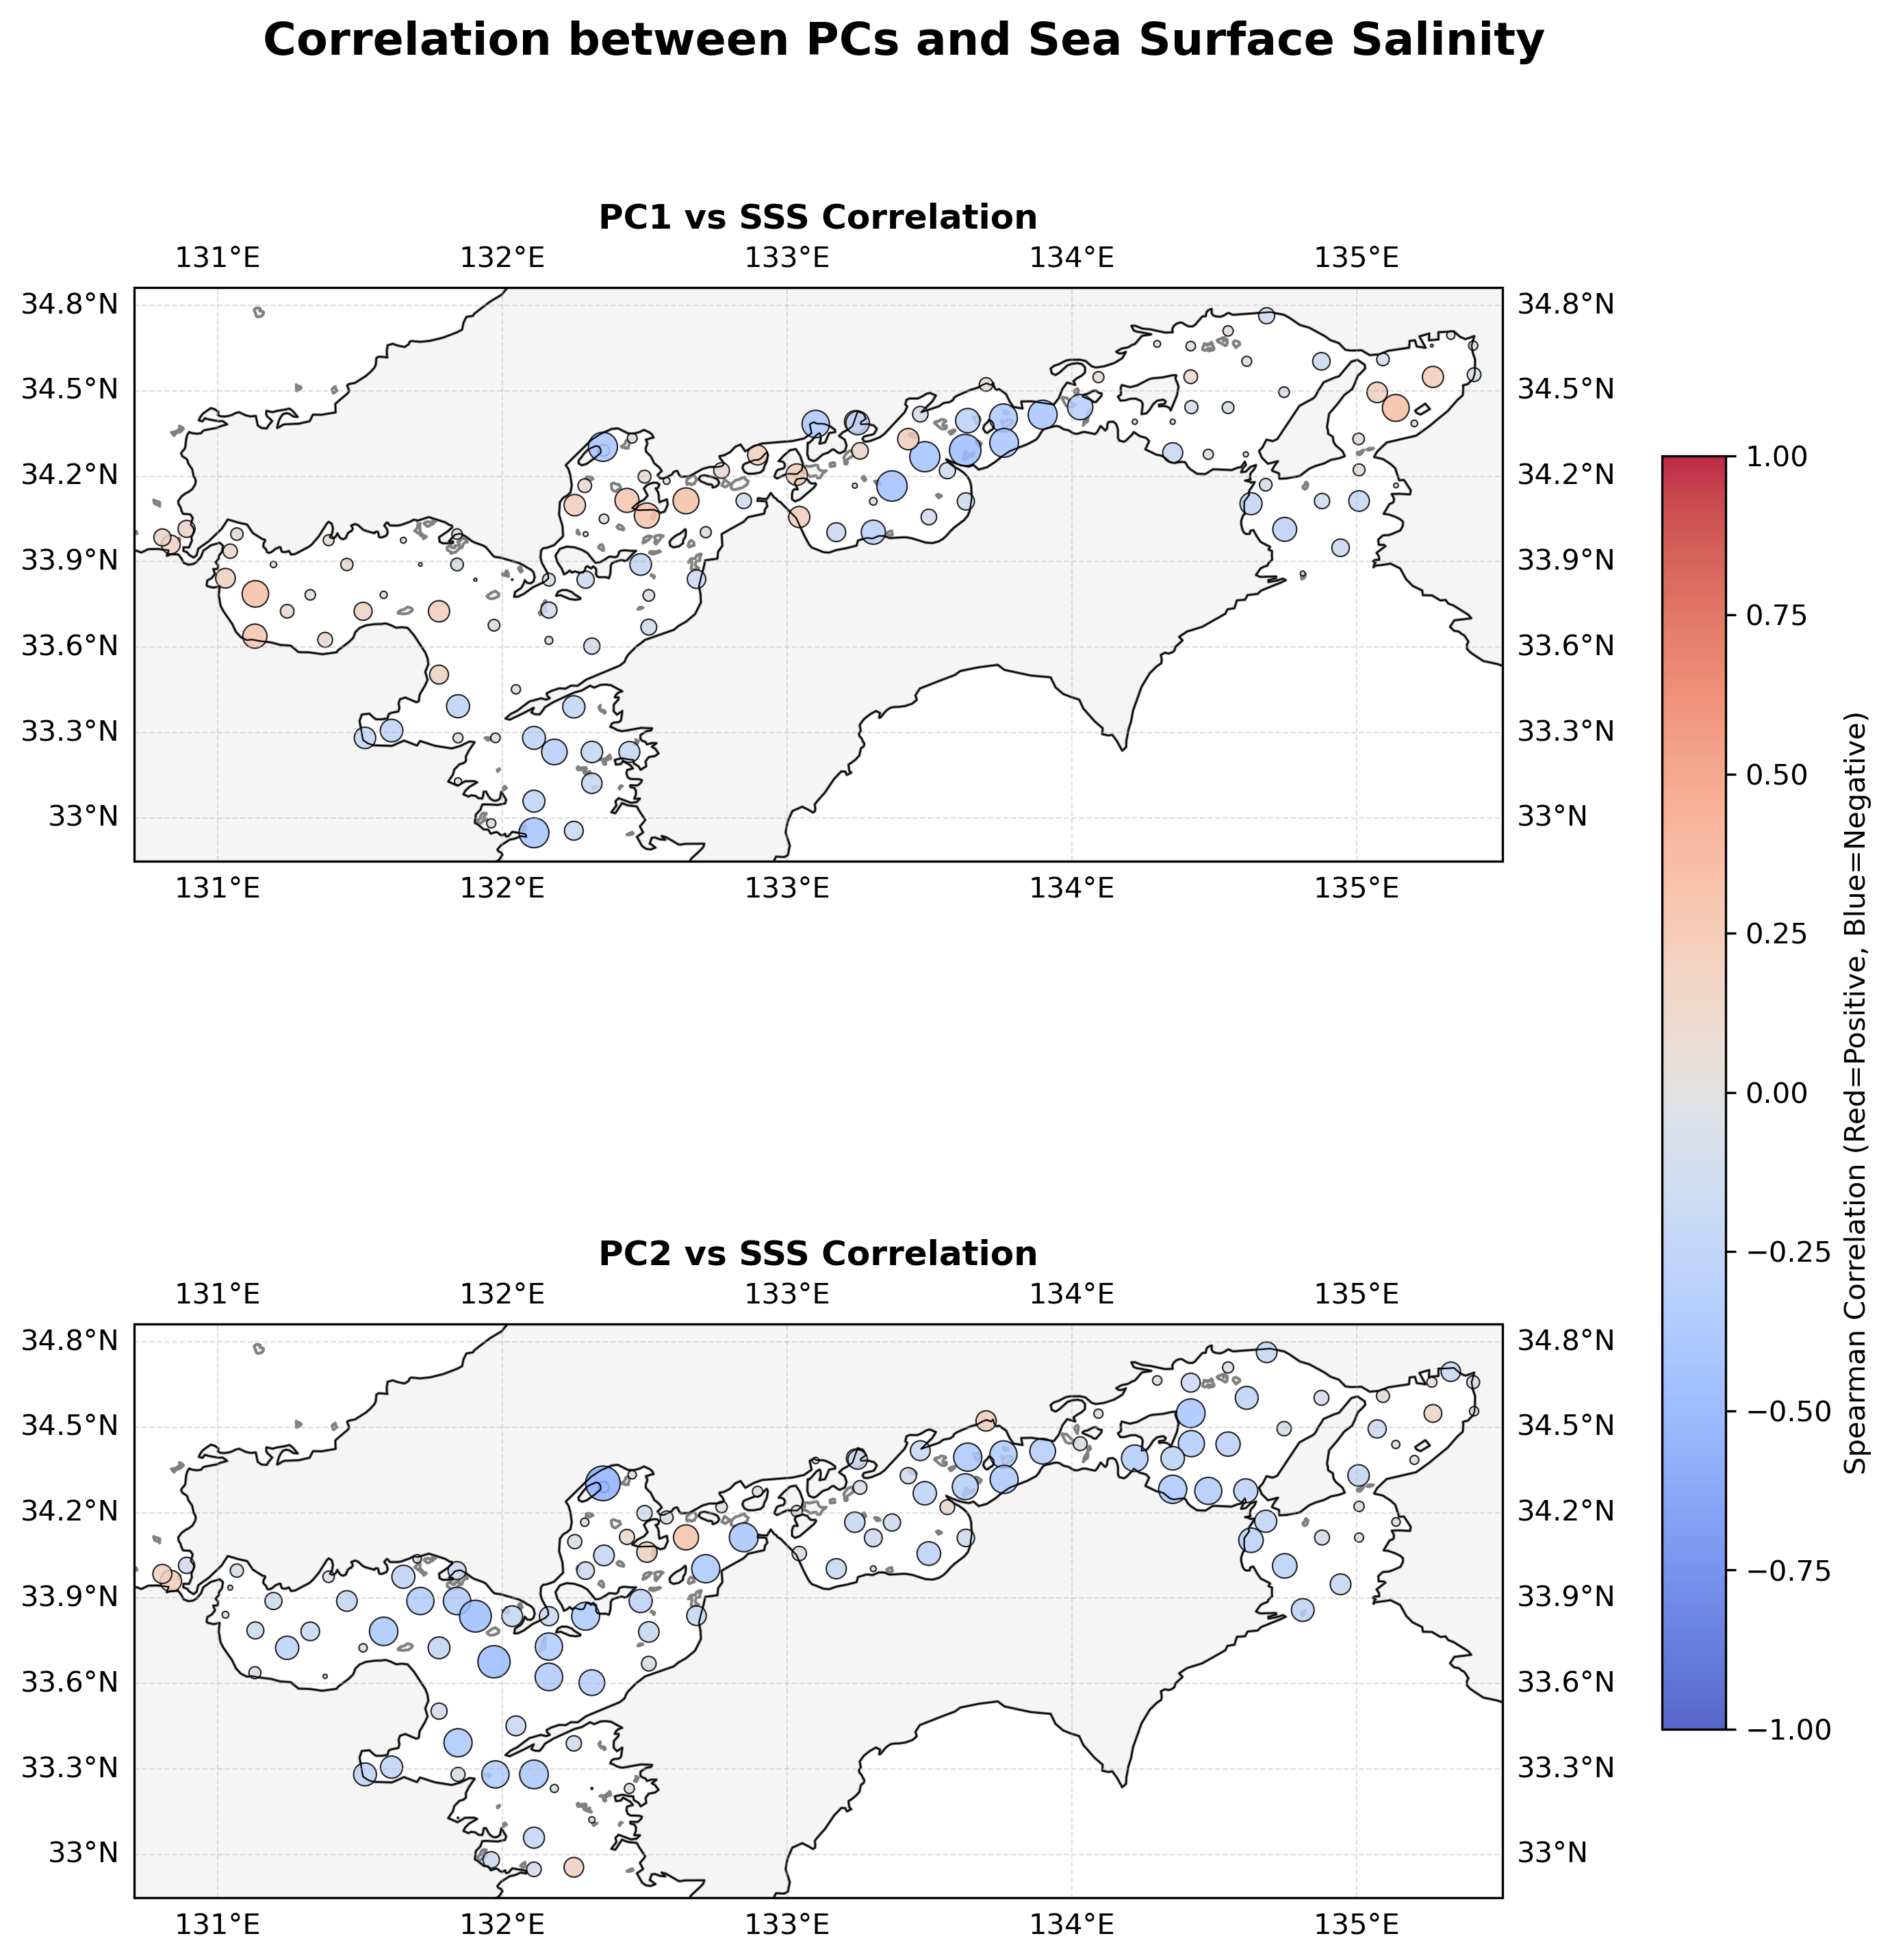

Saved plot to /home/reyha/SIS_Analysis_WSL/figures/pca_corr_SBT.png


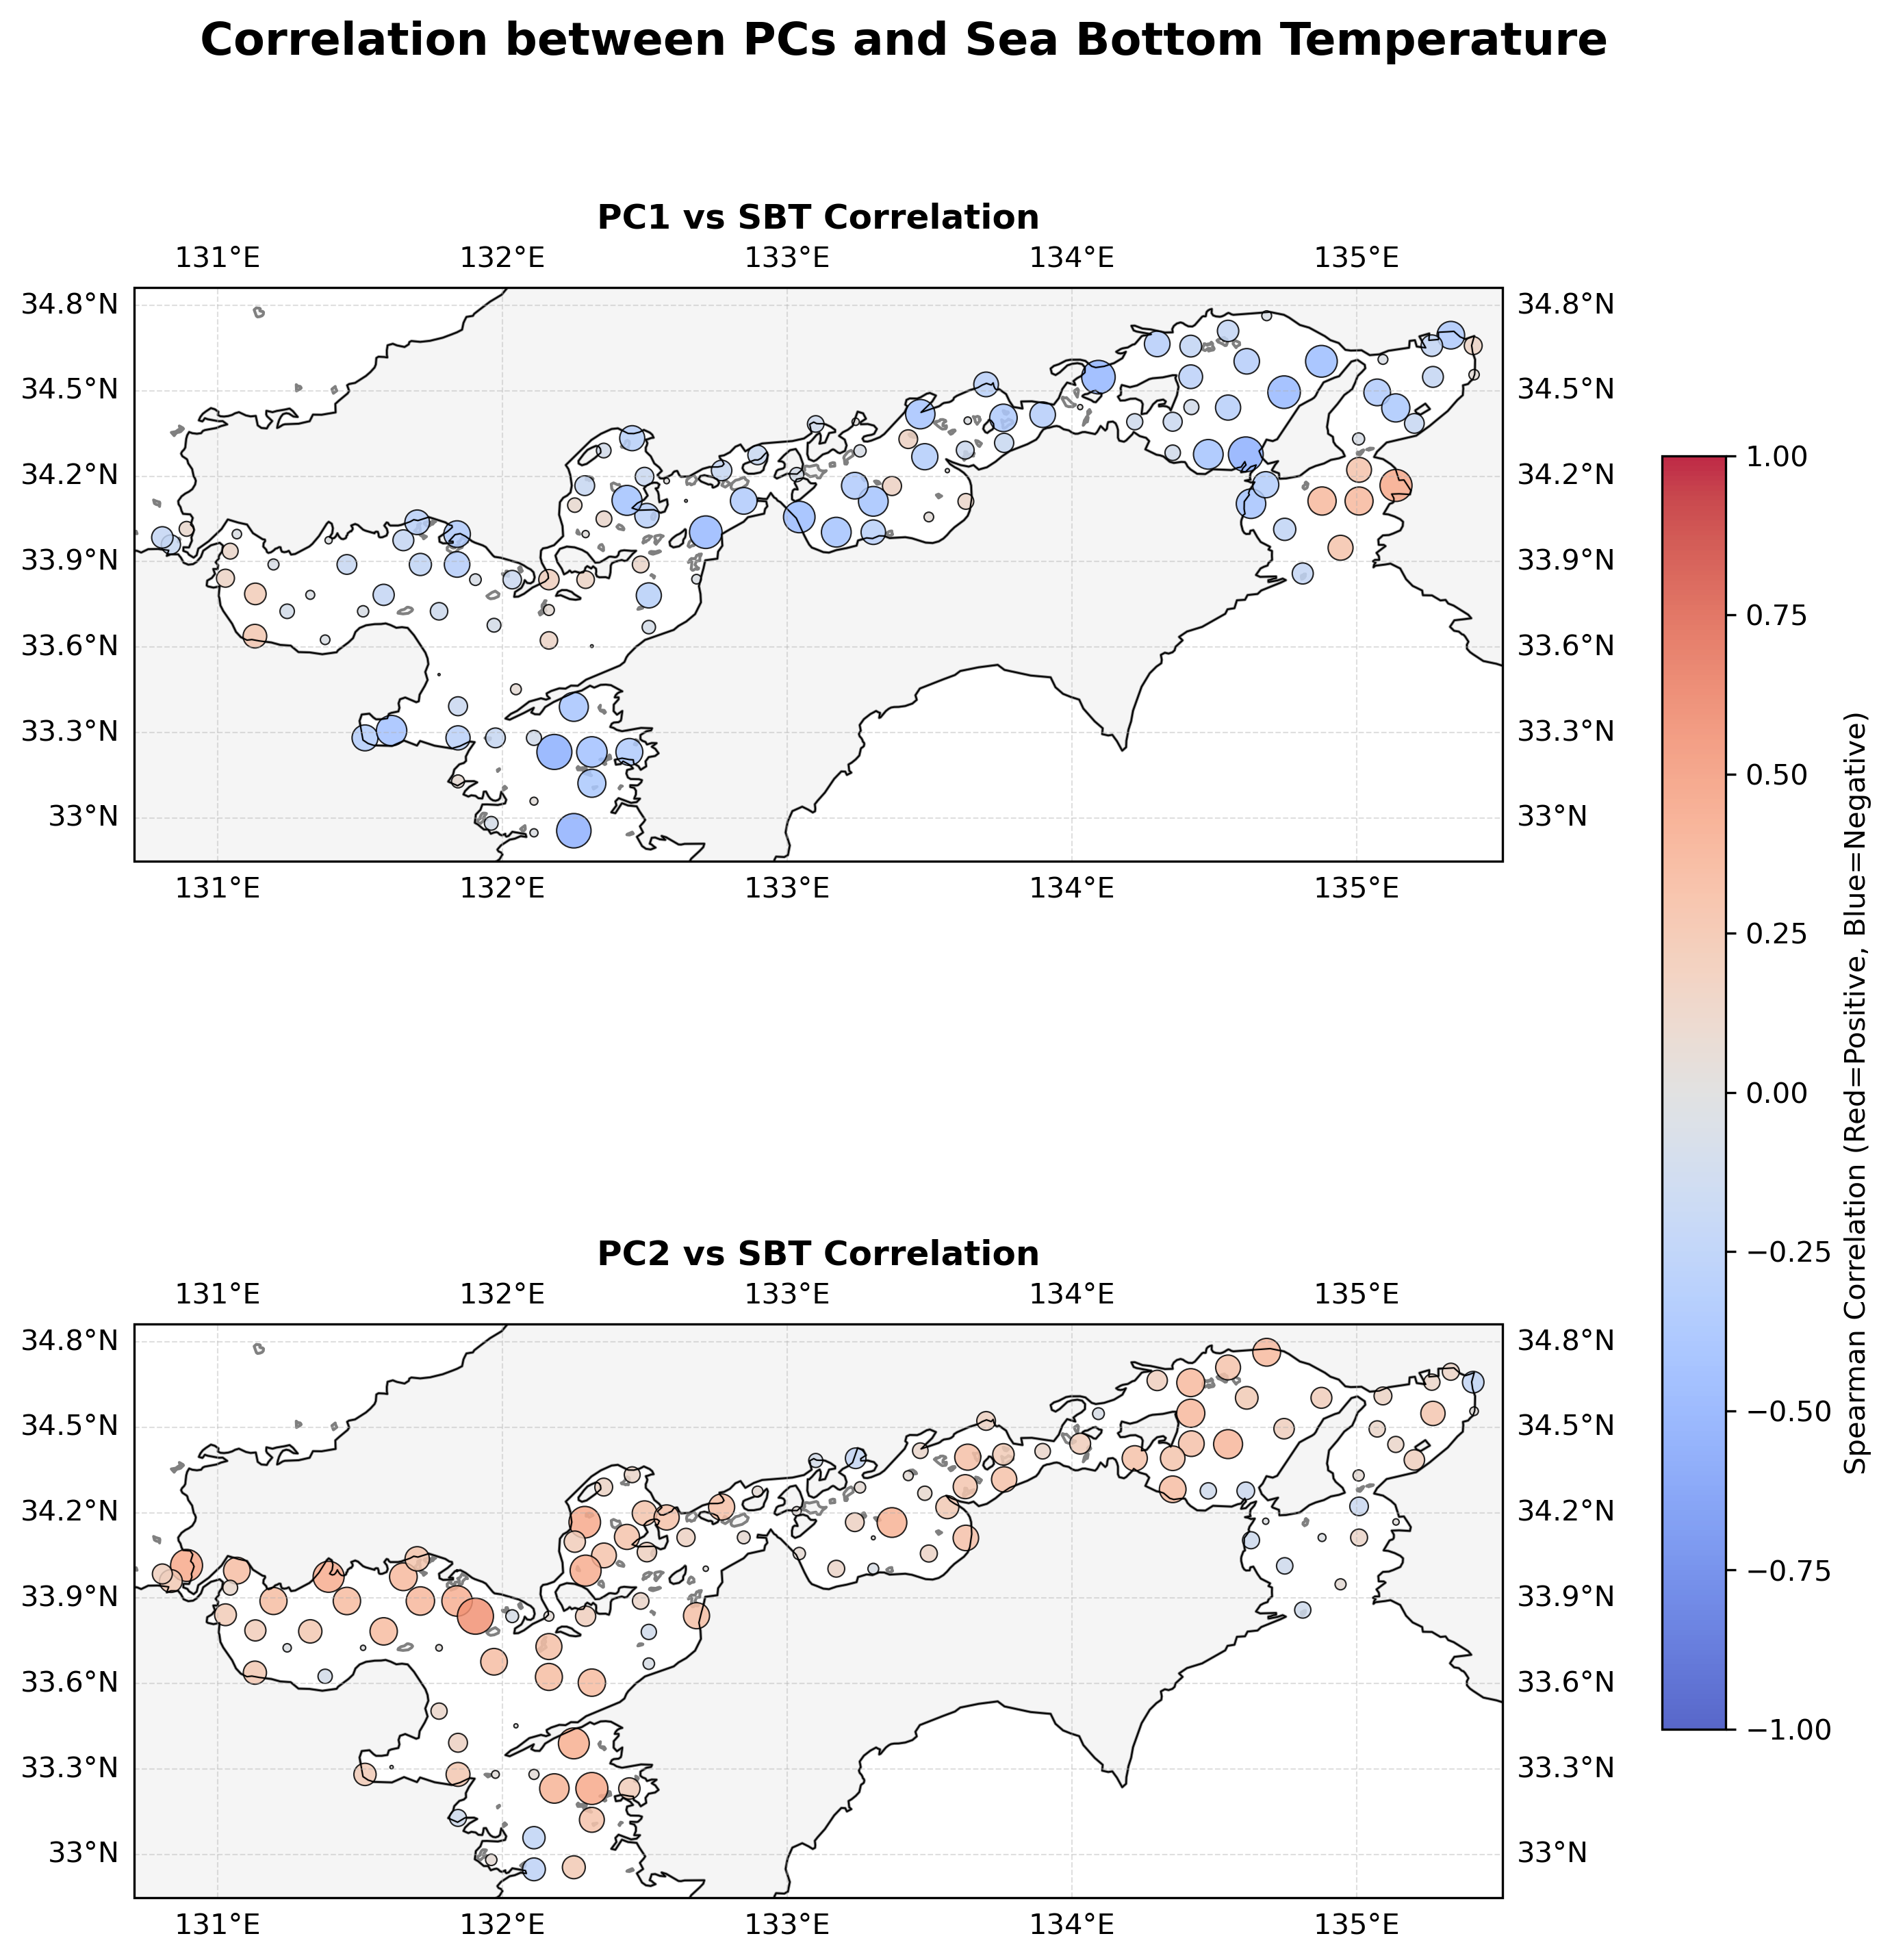

Saved plot to /home/reyha/SIS_Analysis_WSL/figures/pca_corr_SBS.png


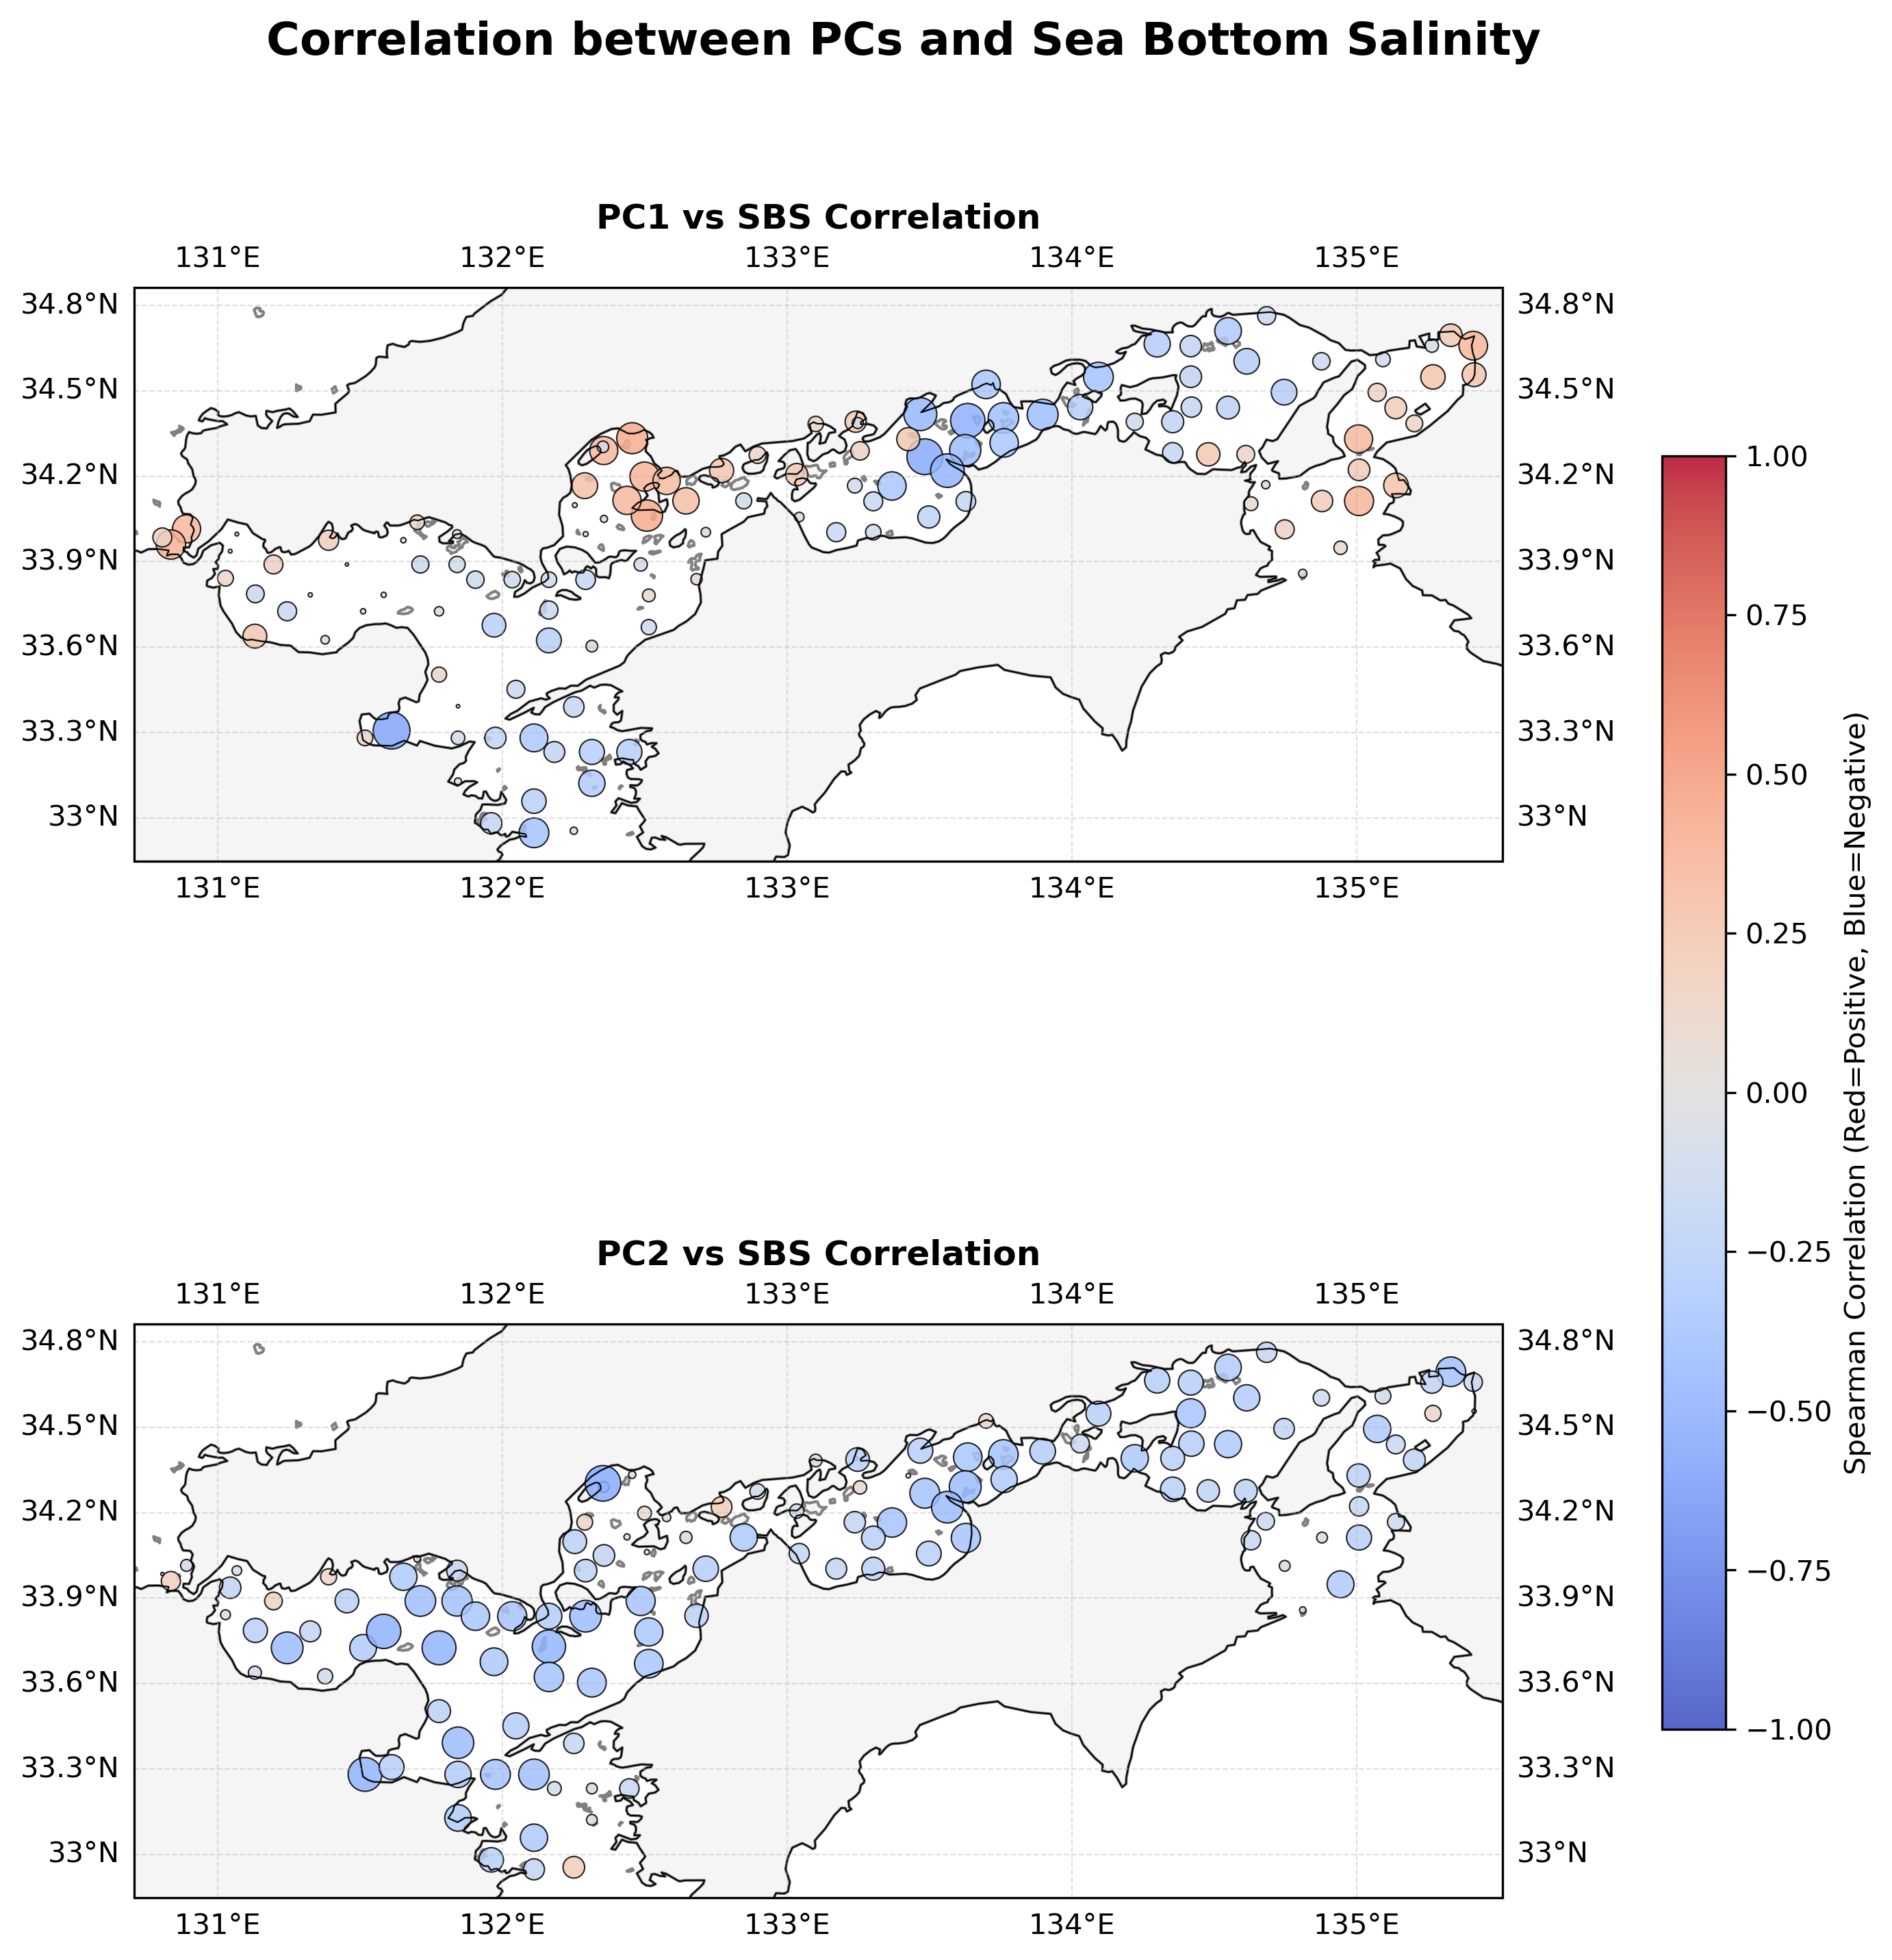

In [ ]:
# 4. Visualization (User Style)

def plot_correlation_maps(gdf, variable_type, title_prefix):
    # variable_type: 'SST', 'SSS', 'SBT', 'SBS'
    
    fig, axes = plt.subplots(2, 1, figsize=(10, 12), subplot_kw={'projection': ccrs.PlateCarree()})
    
    fig.suptitle(f'Correlation between PCs and {title_prefix}', fontsize=16, fontweight='bold', y=0.95)

    components = [
        (f'PC1_{variable_type}_Corr', 'PC1'), 
        (f'PC2_{variable_type}_Corr', 'PC2')
    ]

    for ax, (col, pc_name) in zip(axes, components):
        if col not in gdf.columns:
            continue
            
        pad = 0.1
        min_lon, min_lat, max_lon, max_lat = gdf.total_bounds
        ax.set_extent([min_lon - pad, max_lon + pad, min_lat - pad, max_lat + pad], crs=ccrs.PlateCarree())

        ax.add_feature(cfeature.LAND, facecolor='whitesmoke', edgecolor='gray')
        ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
        ax.gridlines(draw_labels=True, linestyle='--', alpha=0.4, linewidth=0.5)

        # Scatter plot
        # Using correlation range -1 to 1
        sc = ax.scatter(
            gdf.geometry.x,
            gdf.geometry.y,
            c=gdf[col],
            s=gdf[col].abs() * 300,  # Scaled by correlation magnitude
            cmap='PRGn',
            edgecolor='k',
            linewidth=0.5,
            alpha=0.85,
            transform=ccrs.PlateCarree(),
            vmin=-1, vmax=1  # Correlation bounds
        )
        ax.set_title(f'{pc_name} vs {variable_type} Correlation', fontsize=12, fontweight='bold')

    # Reduce vertical spacing
    plt.subplots_adjust(hspace=0.08, top=0.92)

    # Colorbar
    cbar = fig.colorbar(sc, ax=axes.ravel().tolist(), orientation='vertical', fraction=0.04, pad=0.1)
    cbar.set_label('Pearson Correlation (Red=Positive, Blue=Negative)')

    save_path = ProjectPaths.FIGURES_DIR / f'pca_corr_{variable_type}.png'
    plt.savefig(save_path, bbox_inches='tight')
    print(f"Saved plot to {save_path}")
    plt.show()

# Generate plots for all 4 variables
if not corr_map_data.empty:
    plot_correlation_maps(corr_map_data, 'SST', 'Sea Surface Temperature')
    plot_correlation_maps(corr_map_data, 'SSS', 'Sea Surface Salinity')
    plot_correlation_maps(corr_map_data, 'SBT', 'Sea Bottom Temperature')
    plot_correlation_maps(corr_map_data, 'SBS', 'Sea Bottom Salinity')
else:
    print("No correlation map data to plot.")

Generating Grid Plots...
Saved plot to /home/reyha/SIS_Analysis_WSL/figures/pca_PC1_env_corr_grid.png


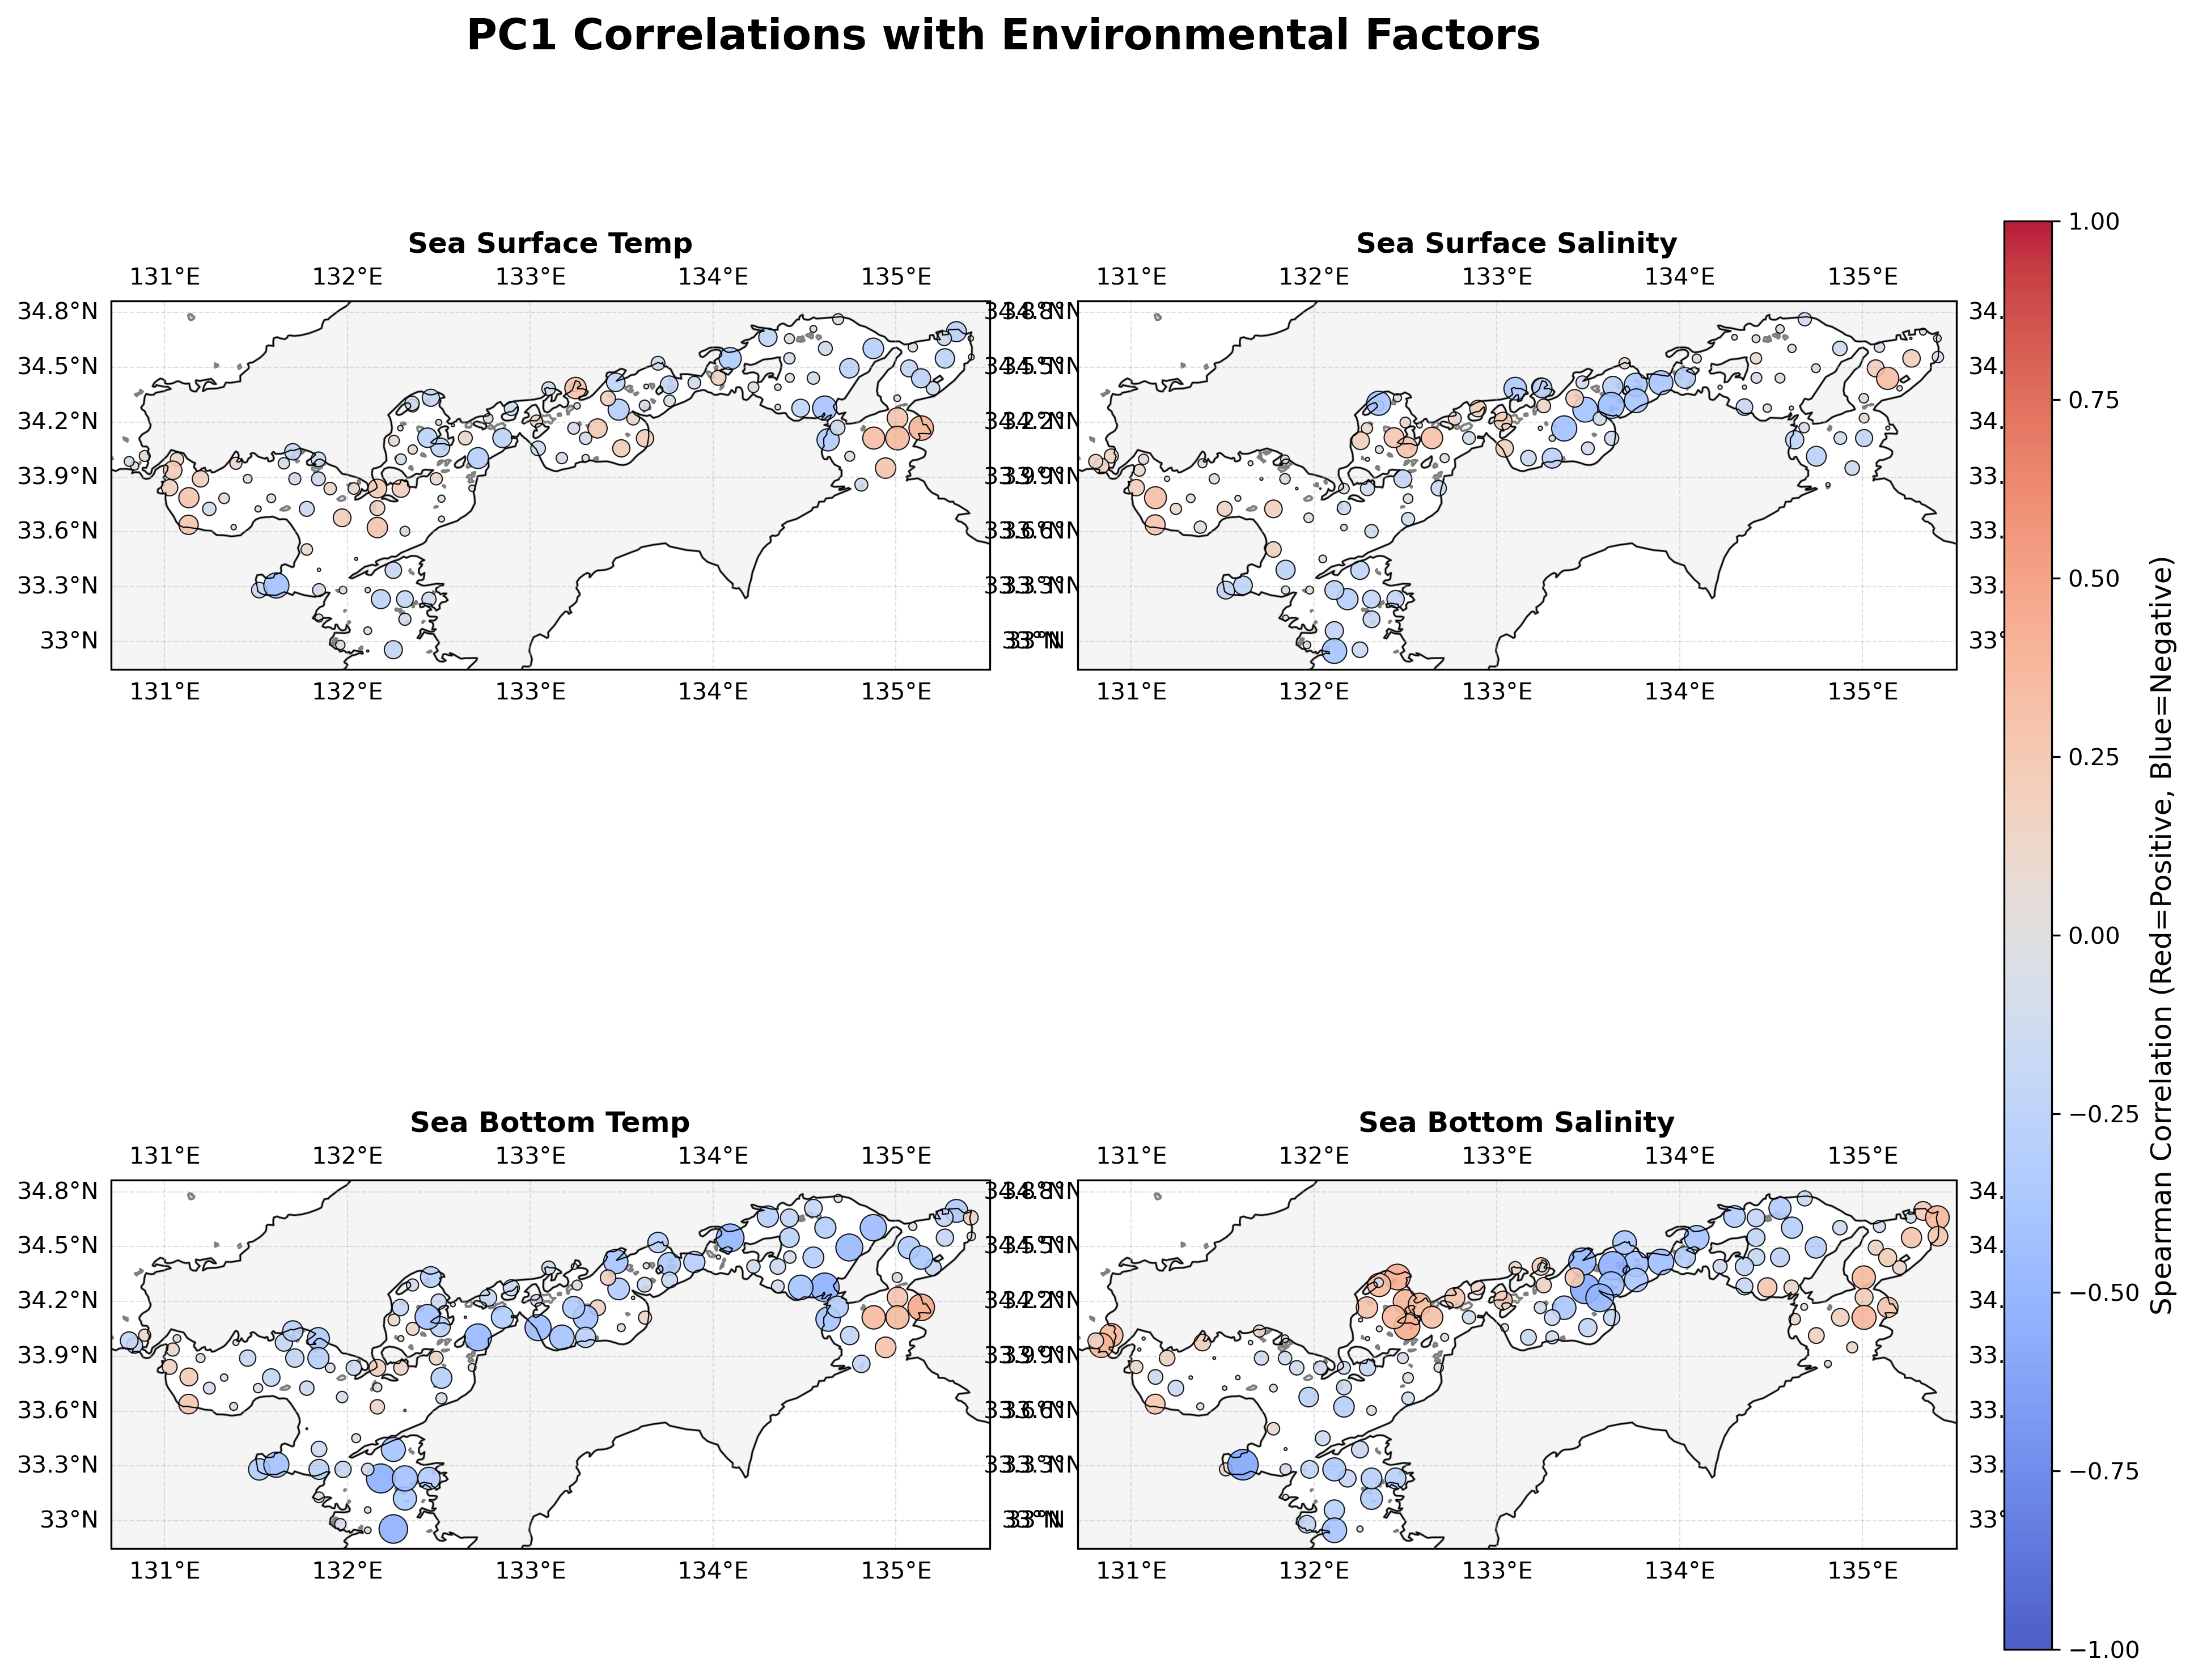

Saved plot to /home/reyha/SIS_Analysis_WSL/figures/pca_PC2_env_corr_grid.png


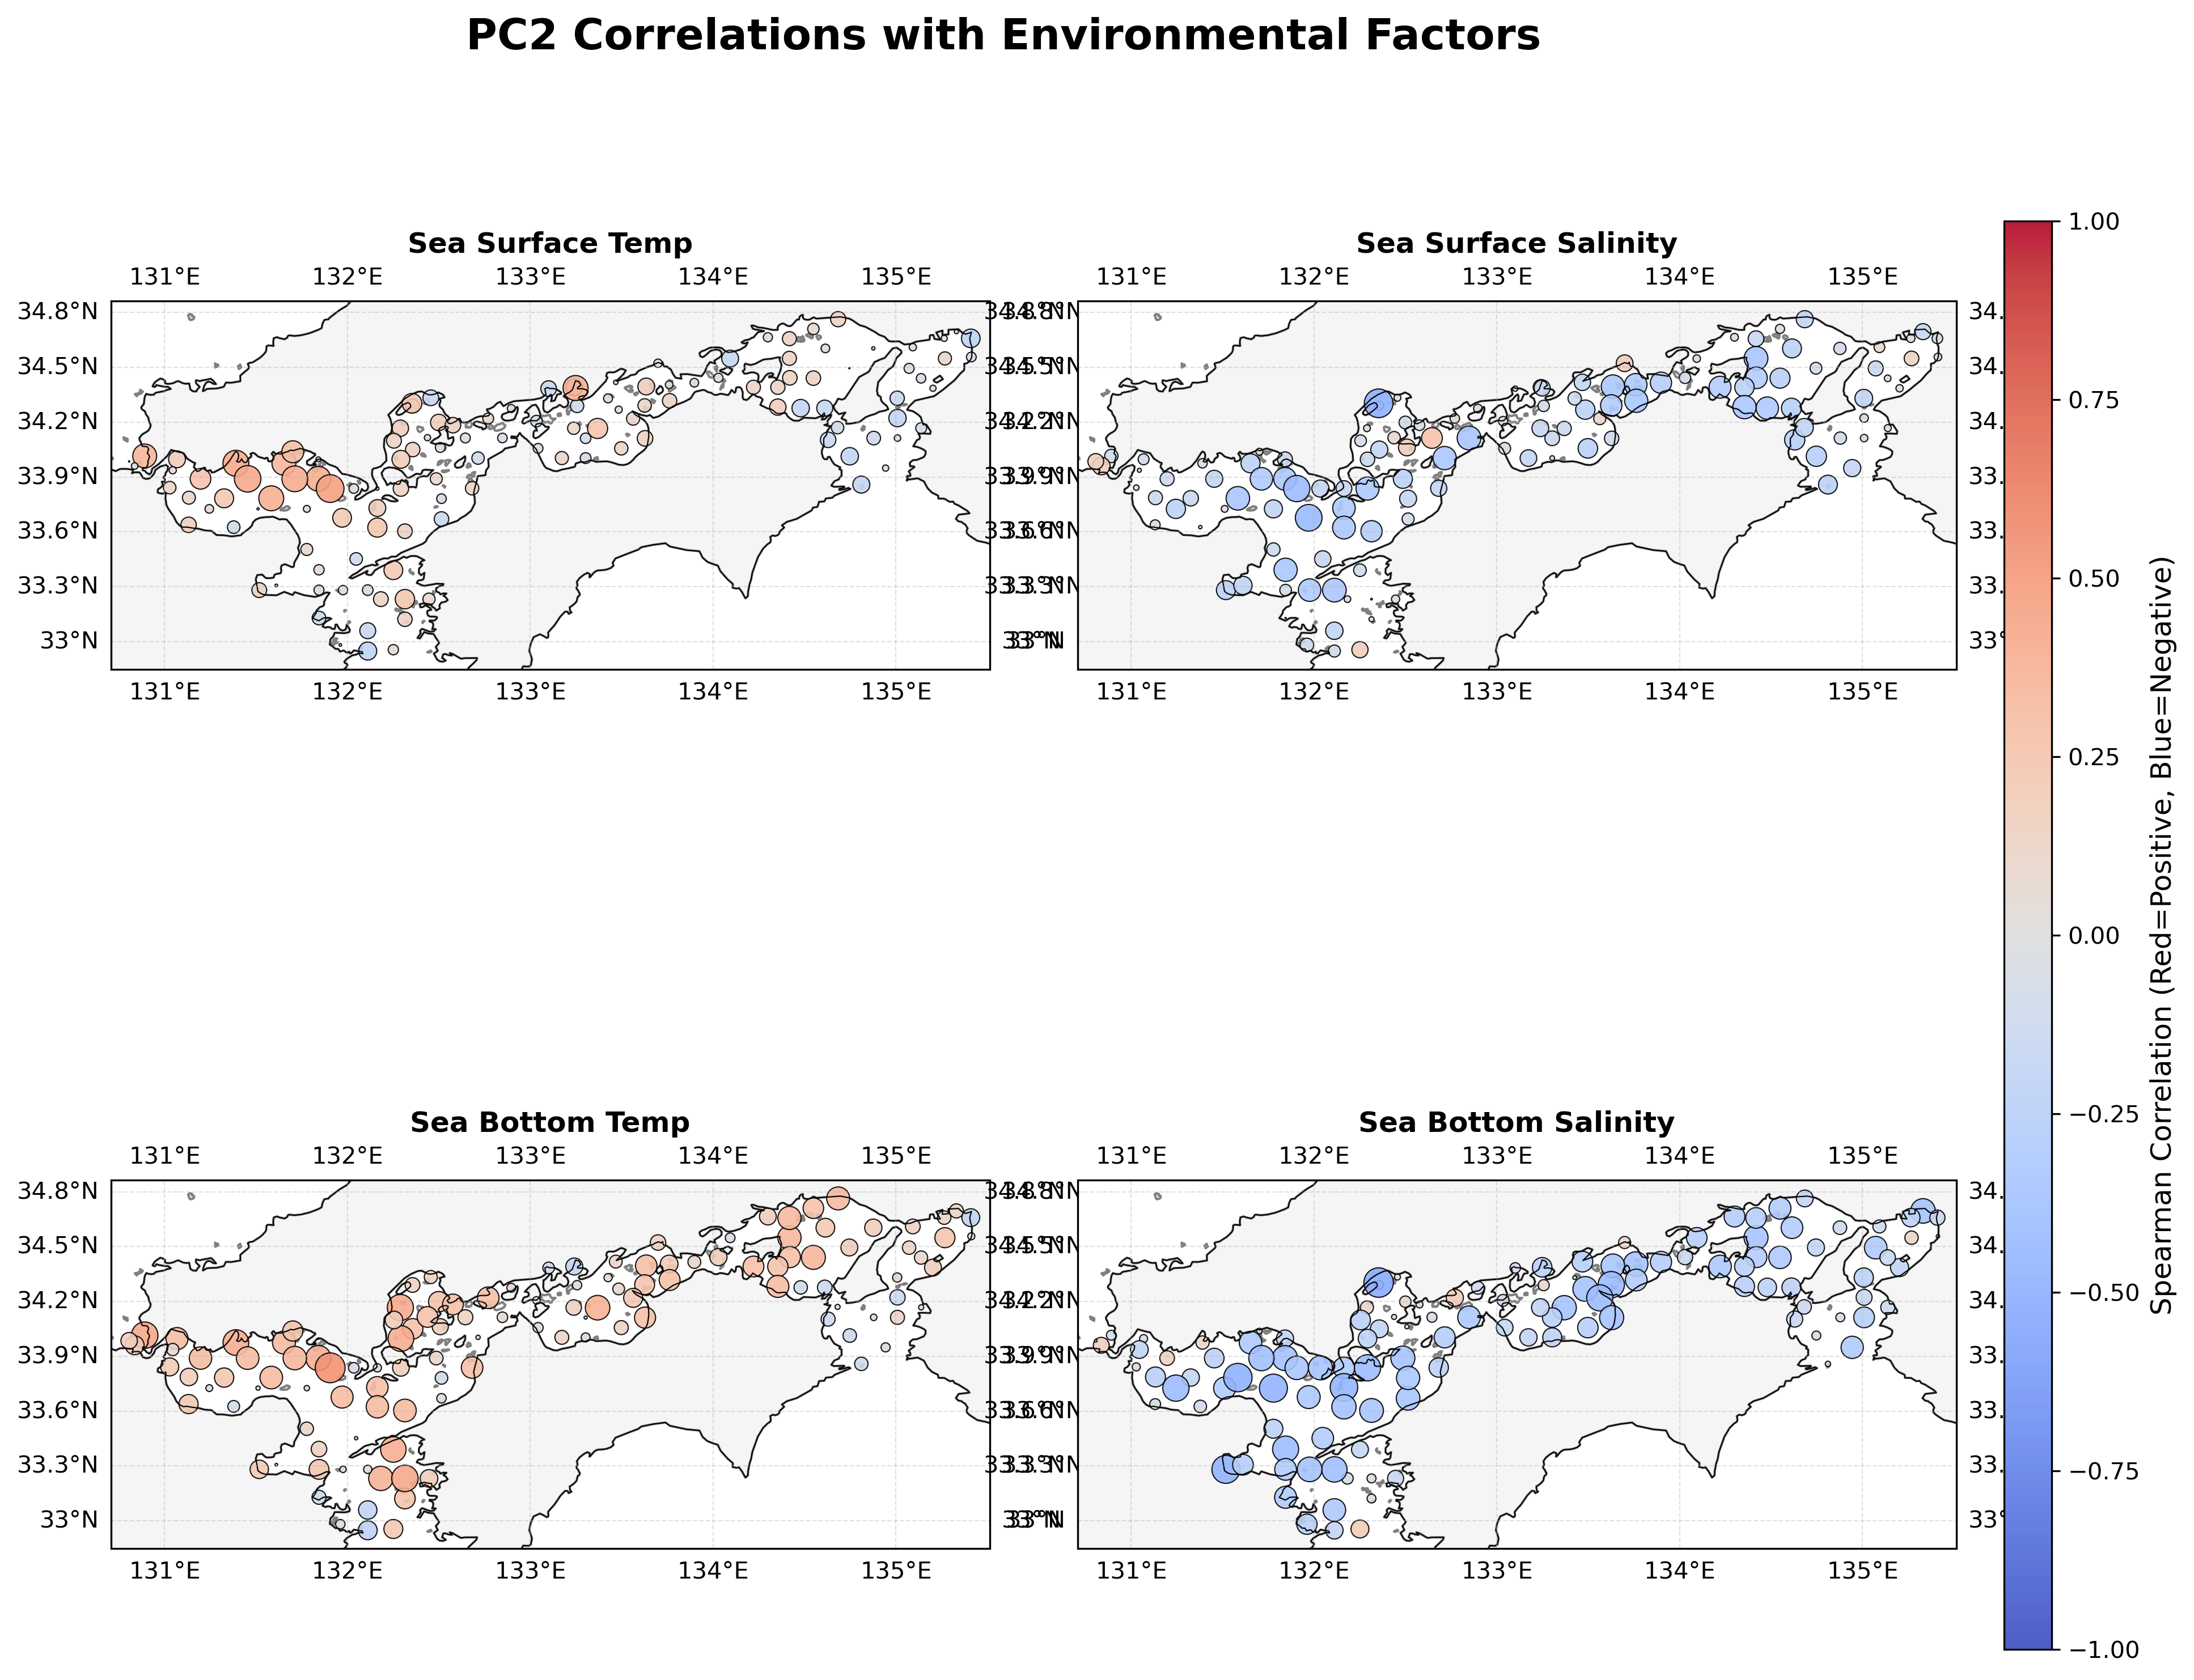

In [ ]:

def plot_pc_correlations(gdf, pc_name):
    # pc_name: 'PC1' or 'PC2'
    
    fig, axes = plt.subplots(2, 2, figsize=(14, 12), subplot_kw={'projection': ccrs.PlateCarree()})
    fig.suptitle(f'{pc_name} Correlations with Environmental Factors', fontsize=18, fontweight='bold', y=0.95)

    params = [
        ('SST', f'{pc_name}_SST_Corr', 'Sea Surface Temp'),
        ('SSS', f'{pc_name}_SSS_Corr', 'Sea Surface Salinity'),
        ('SBT', f'{pc_name}_SBT_Corr', 'Sea Bottom Temp'),
        ('SBS', f'{pc_name}_SBS_Corr', 'Sea Bottom Salinity')
    ]

    for ax, (var_name, col, title) in zip(axes.ravel(), params):
        if col not in gdf.columns:
            ax.text(0.5, 0.5, "Data Missing", transform=ax.transAxes, ha='center')
            continue
            
        pad = 0.1
        min_lon, min_lat, max_lon, max_lat = gdf.total_bounds
        ax.set_extent([min_lon - pad, max_lon + pad, min_lat - pad, max_lat + pad], crs=ccrs.PlateCarree())

        ax.add_feature(cfeature.LAND, facecolor='whitesmoke', edgecolor='gray')
        ax.add_feature(cfeature.COASTLINE, linewidth=0.5)
        ax.gridlines(draw_labels=True, linestyle='--', alpha=0.4, linewidth=0.5)

        # Scatter plot
        sc = ax.scatter(
            gdf.geometry.x,
            gdf.geometry.y,
            c=gdf[col],
            s=gdf[col].abs() * 300,
            cmap='PRGn',
            edgecolor='k',
            linewidth=0.5,
            alpha=0.9,
            transform=ccrs.PlateCarree(),
            vmin=-1, vmax=1
        )
        ax.set_title(title, fontsize=12, fontweight='bold')

    plt.subplots_adjust(hspace=0.2, wspace=0.1, top=0.90)

    # Global Colorbar
    cbar_ax = fig.add_axes([0.92, 0.15, 0.02, 0.7])
    cbar = fig.colorbar(sc, cax=cbar_ax, orientation='vertical')
    cbar.set_label('Pearson Correlation (Red=Positive, Blue=Negative)', fontsize=12)

    save_path = ProjectPaths.FIGURES_DIR / f'pca_{pc_name}_env_corr_grid.png'
    plt.savefig(save_path, bbox_inches='tight')
    print(f"Saved plot to {save_path}")
    plt.show()

# Generate for PC1 and PC2
print("Generating Grid Plots...")
if not corr_map_data.empty:
    plot_pc_correlations(corr_map_data, 'PC1')
    plot_pc_correlations(corr_map_data, 'PC2')
